# Computer Vision - P3

### *Carefully read the following instructions before start coding.*

==============================================================================================
## **Practice 3: Image and Video Segmentation & Templeta Matching**

==============================================================================================

### The main topics of P3 are:

- Image segmentation.

- Background subtraction.

- Template Matching





In [210]:
#
# First, let's load some libraries used in the practice
#
# Example
import numpy as np
import skimage
from skimage import io
import matplotlib.pyplot as plt
import matplotlib.animation as animation

## **Image Segmentation**

In this section we will apply different image segmentation methods (e.g., Felzenswhalbs, Slic and Quickshift) based on the clustering of points corresponding to the pixels and analyze their differences.

**Hint**: 
- Different image segmentation methods are available in [`skimage.segmentation`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html).
- Use the function [`segmentation.mark_boundaries`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.mark_boundaries) to visualize the boundaries of the segments.
- Use the inline pluggin to visualize images (`%matplotlib inline`).

<img src="images_p3/image_Segmentation.png" width=600>

### **Felzenszwalb Image Segmentation**

**a)** Apply the Felzenszwalb segmentation method to `images/hogwarts.jpeg` using `scale=100`, `sigma=0.5`, and `min_size=50`.
- Visualize the segmentation results using `mark_boundaries` to highlight segment boundaries.
- Count the number of segments detected.
- Experiment with different parameter values and analyze their effects on the segmentation results.

Expected result is illustrated below:

<img src="images_p3/bunch-of-fresh-fruit_resut.jpg" width=700>

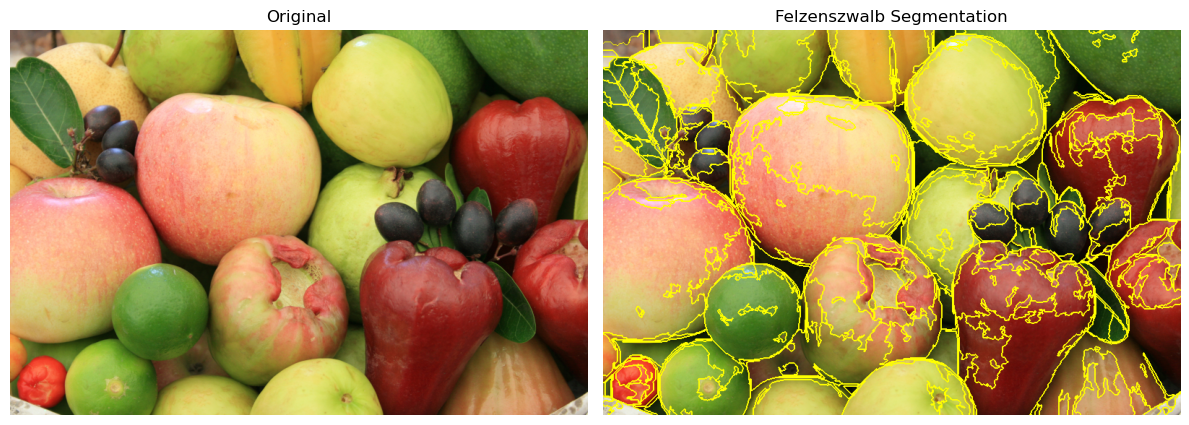

Number of Segments:  446


In [211]:
# Import necessary libraries
import numpy as np
from skimage import io
from skimage.segmentation import felzenszwalb, mark_boundaries
import matplotlib.pyplot as plt

img = io.imread("images_p3/bunch-of-fresh-fruit.png")
segments_fz = felzenszwalb(img, scale=100, sigma=0.5, min_size=50)

# Mostrar Figura
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img)
axes[0].set_title('Original')
axes[0].axis('off')

axes[1].imshow(mark_boundaries(img, segments_fz))
axes[1].set_title('Felzenszwalb Segmentation')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("Number of Segments: ", len(np.unique(segments_fz)))

**b) Exploring Felzenszwalb Segmentation Parameters**

Create a function to explore at least three different parameter combinations for the Felzenszwalb segmentation method using the image `images_p3/bunch-of-fresh-fruit.png`. 
- The function should receive the input image and a list of parameter combinations, resize the image to one-third of its original dimensions, visualize the segmentation results with marked boundaries, and print the number of segments detected for each combination.

Experiment with different values of `scale`, `sigma`, and `min_size` to identify the combination that produces the best segmentation results.

**Reflect on the following questions:**

- Is converting the image to grayscale necessary for image segmentation?
- Is converting the image to floating-point format necessary?
- Which parameter combination produces the best results according to your subjective assessment?
- How does each parameter (`scale`, `sigma`, and `min_size`) affect the segmentation results?
- Does reducing the image resolution affect the optimal parameter values? Explain why.

Expected result is illustrated below (you don't need to use the same parameters):

<img src="images_p3/bunch-of-fresh-fruit_resut2.jpg" width=800>

Combinación 1 (Scale=150, Sigma=1.0, Min_size=50): 85 segmentos detectados.
Combinación 2 (Scale=250, Sigma=1.5, Min_size=100): 34 segmentos detectados.
Combinación 3 (Scale=300, Sigma=2.0, Min_size=150): 21 segmentos detectados.


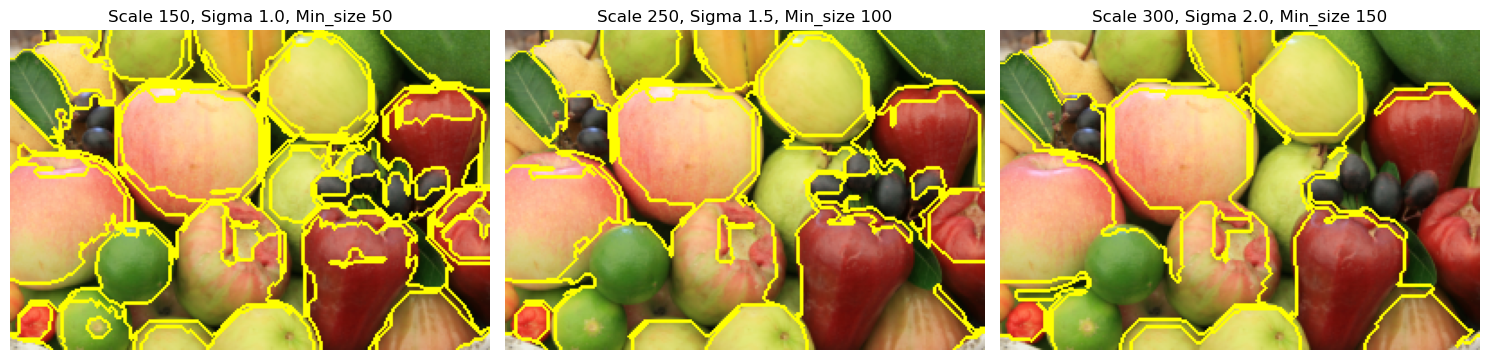

In [212]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import io, transform
from skimage.segmentation import felzenszwalb, mark_boundaries

def explore_felzenszwalb_parameters(image, params_list):
    # channel_axis=-1 indica que el último eje corresponde a los canales de color (RGB)
    resized_image = transform.rescale(image, 1/3.0, channel_axis=-1)
    
    fig, axes = plt.subplots(1, len(params_list), figsize=(15, 5))
    
    for idx, (scale_val, sigma_val, min_size_val) in enumerate(params_list):
        
        segments = felzenszwalb(resized_image, scale=scale_val, sigma=sigma_val, min_size=min_size_val)
        
        # Imprimir el número de segmentos
        print(f"Combinación {idx+1} (Scale={scale_val}, Sigma={sigma_val}, Min_size={min_size_val}): {len(np.unique(segments))} segmentos detectados.")
        
        axes[idx].imshow(mark_boundaries(resized_image, segments))
        axes[idx].set_title(f'Scale {scale_val}, Sigma {sigma_val}, Min_size {min_size_val}')
        axes[idx].axis('off')
        
    plt.tight_layout()
    plt.show()

combinaciones = [(150, 1.0, 50), (250, 1.5, 100), (300, 2.0, 150)]
explore_felzenszwalb_parameters(img, combinaciones)

### **SLIC — K-Means-Based Image Segmentation**

**c)** Segment the image `images_p3/bunch-of-fresh-fruit.png` using the SLIC algorithm implemented in [`skimage.segmentation.slic`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.slic).

1. Apply SLIC using the following parameters: `n_segments=250`, `compactness=10`, `sigma=1`, and `start_label=1`.
2. Visualize the original image alongside the segmented image, using [`mark_boundaries`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.mark_boundaries) to highlight the boundaries between segments.
3. Print the total number of segments detected.

Expected result is illustrated below:

<img src="images_p3/bunch-of-fresh-fruit_resut3.jpg" width=800>


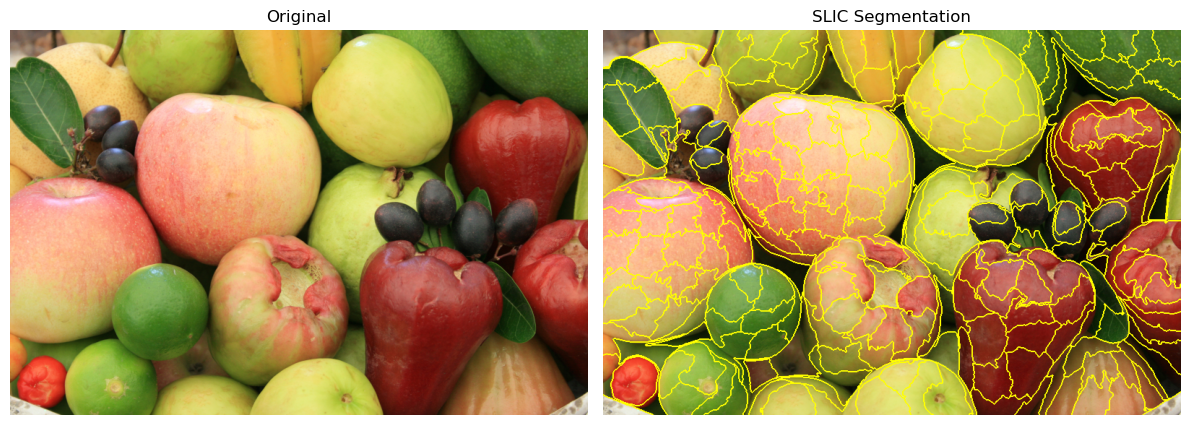

Number of Segments:  219


In [213]:
# Import necessary libraries
from skimage import io, segmentation, color
import matplotlib.pyplot as plt
import numpy as np

segments_slic = segmentation.slic(img, n_segments=250, compactness=10, sigma=1, start_label=1)

# Mostrar Figura
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img)
axes[0].set_title('Original')
axes[0].axis('off')

axes[1].imshow(mark_boundaries(img, segments_slic))
axes[1].set_title('SLIC Segmentation')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("Number of Segments: ", len(np.unique(segments_slic)))

**d)** Create a function to explore at least three different parameter combinations for the SLIC segmentation algorithm.
- Identify the combination that produces the best results. 
- The function should receive the input image and a list of parameter combinations, resize the image to one-third of its original dimensions, visualize the segmentation results with marked boundaries, and print the number of segments detected for each combination.

Expected result is illustrated below (you don't need to use the same parameters):

<img src="images_p3/bunch-of-fresh-fruit_resut4.jpg" width=800>

n_segments=20, compactness=10): 17 segmentos.
n_segments=50, compactness=30): 49 segmentos.
n_segments=35, compactness=25): 30 segmentos.


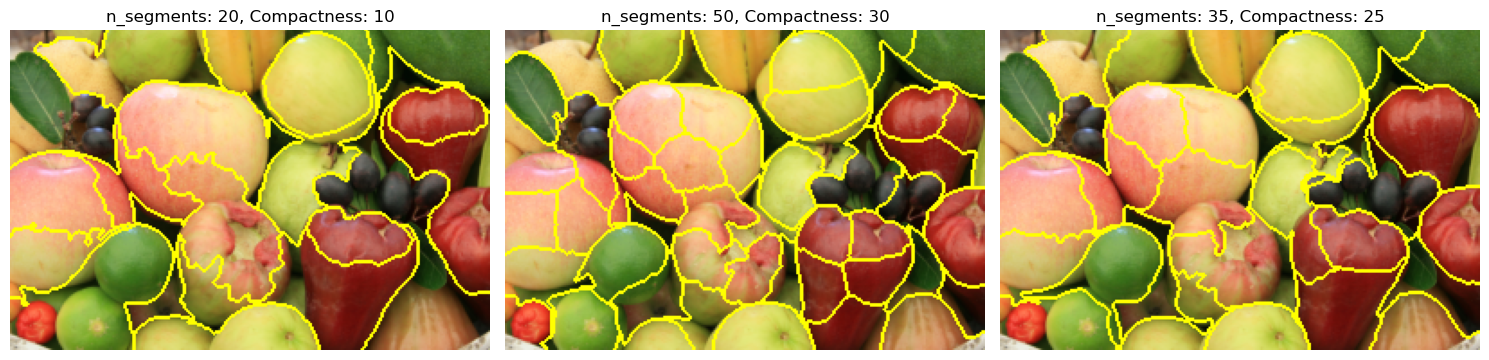

In [214]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import io, segmentation, transform
from skimage.segmentation import mark_boundaries

def explore_slic_parameters(image, params_list):
    # Redimensionar la imagen a un tercio de sus dimensiones originales
    resized_image = transform.rescale(image, 1/3.0, channel_axis=-1)
    
    # Preparar la figura
    fig, axes = plt.subplots(1, len(params_list), figsize=(15, 5))
    
    for i, (n_seg, comp) in enumerate(params_list):
        
        segments = segmentation.slic(resized_image, n_segments=n_seg, compactness=comp, sigma=1, start_label=1)
        
        # Imprimir número de segmentos detectados
        print(f"n_segments={n_seg}, compactness={comp}): {len(np.unique(segments))} segmentos.")
        
        # Visualizar los resultados con mark_boundaries
        axes[i].imshow(mark_boundaries(resized_image, segments))
        axes[i].set_title(f'n_segments: {n_seg}, Compactness: {comp}')
        axes[i].axis('off')
        
    plt.tight_layout()
    plt.show()

parameter_combinations = [(20, 10), (50, 30), (35, 25)]

explore_slic_parameters(img, parameter_combinations)

### **Quickshift Image Segmentation**

**e)** Apply the [Quickshift segmentation algorithm](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.quickshift) to the original image, `images_p3/bunch-of-fresh-fruit.png`.

- Create a function that explores different `kernel_size` values (`1`, `3`, `5`, and `7`), keeping `max_dist=6` and `ratio=0.5` fixed. 
- For each value, visualize the segmentation results with marked boundaries using [`mark_boundaries`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.mark_boundaries) and print the number of segments detected.

Expected result is illustrated below:

<img src="images_p3/bunch-of-fresh-fruit_resut5.jpg" width=800>


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import io, segmentation, color
from skimage.segmentation import mark_boundaries

def explore_quickshift_parameters(image, kernel_sizes):
    fig, axes = plt.subplots(1, len(kernel_sizes), figsize=(15, 5))
    
    for idx, k_size in enumerate(kernel_sizes):
        segments = segmentation.quickshift(image, kernel_size=k_size, max_dist=6, ratio=0.5)
        
        # Imprimir el número de segmentos
        print(f"Kernel size = {k_size}: {len(np.unique(segments))} segmentos detectados.")
        
        axes[idx].imshow(mark_boundaries(image, segments))
        axes[idx].set_title(f'Kernel size: {k_size}')
        axes[idx].axis('off')
        
    plt.tight_layout()
    plt.show()

kernels = [1, 3, 5, 7]
explore_quickshift_parameters(img, kernels)

Kernel size = 1: 6727 segmentos detectados.
Kernel size = 3: 1427 segmentos detectados.


### **Comparison of Image Segmentation Algorithms**

**f)** Select the best parameter settings for the Felzenszwalb and SLIC segmentation algorithms based on your previous experiments. 

Apply both algorithms to the following three versions of `images_p3/bunch-of-fresh-fruit.png`:

1. **Original image:** Use the image without modifications.
2. **Salt-and-pepper noise:** Add noise using `util.random_noise(image, mode='s&p', amount=0.05)`.
3. **Smoothed noisy image:** Apply a Gaussian smoothing filter to the noisy image using `filters.gaussian` with `sigma=2`.

Visualize the segmentation results using `mark_boundaries`. Arrange the results in a \(2 x 3\) subplot grid, with one row for each algorithm and one column for each image version. Print the number of segments detected in each case.

**Reflect on the results:** How does salt-and-pepper noise affect segmentation? Does Gaussian smoothing improve the results? Which algorithm is more robust to noise, and why?

Expected result is illustrated below (**feel free to fine tune the parameters for best results**):

<img src="images_p3/bunch-of-fresh-fruit_resut6.jpg" width=1000>

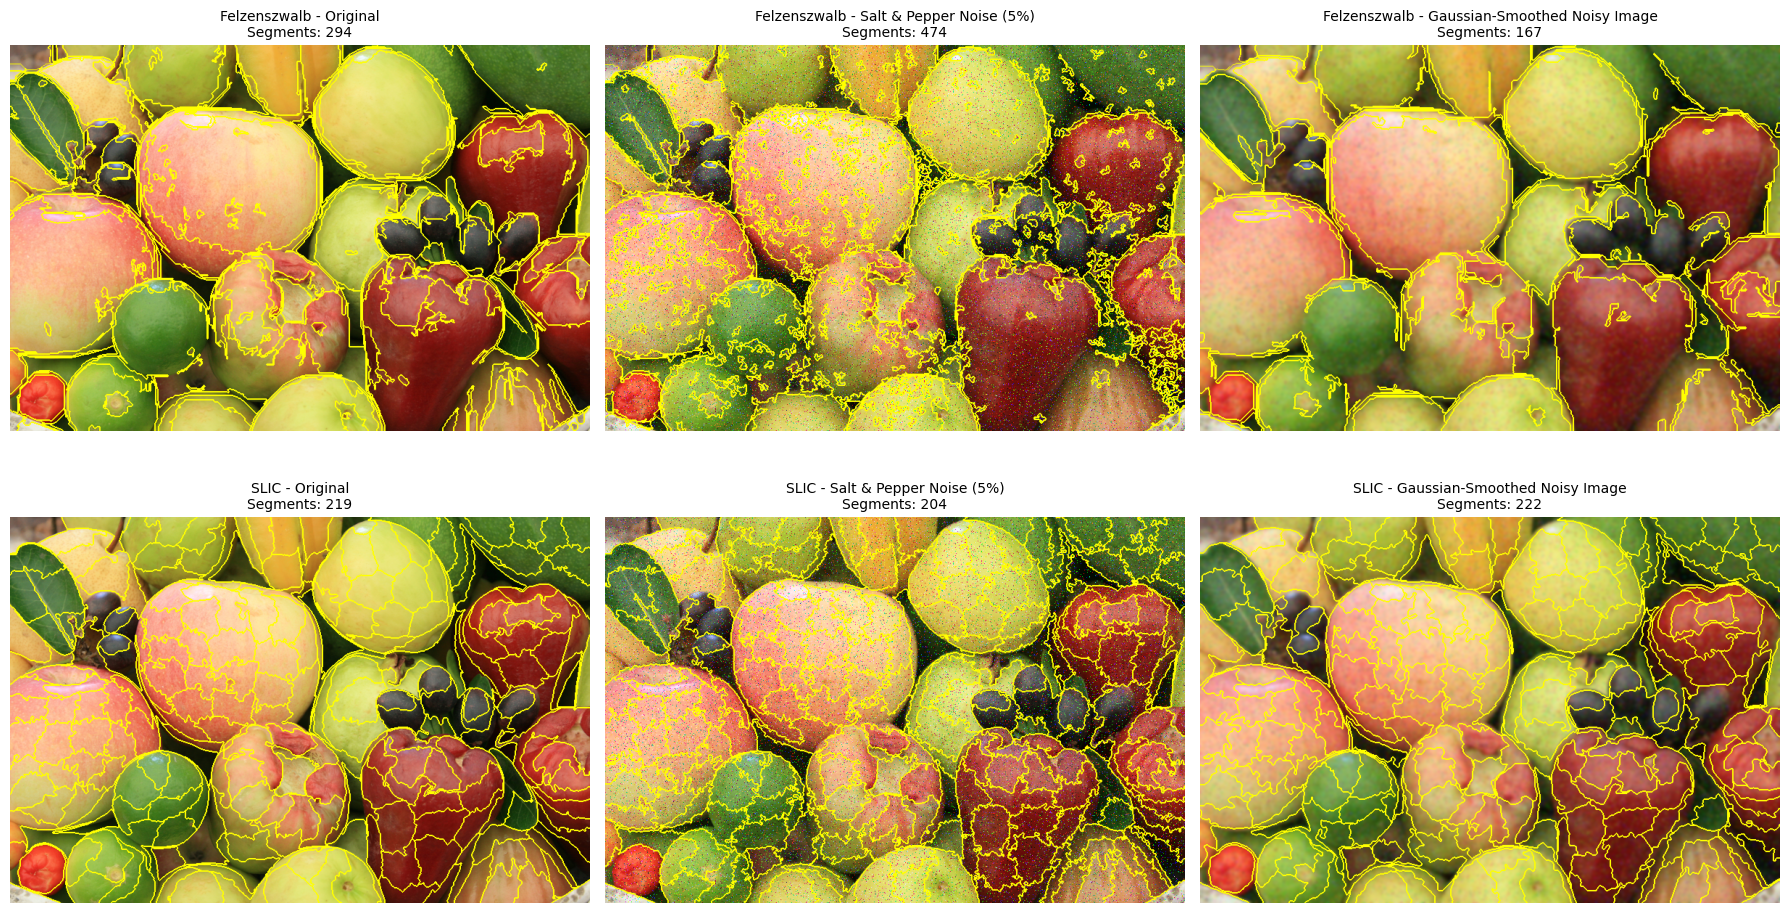

--- Resultados de Felzenszwalb ---
Original: X segmentos
Ruidosa: Y segmentos
Suavizada: Z segmentos


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import io, segmentation, util, filters
from skimage.segmentation import mark_boundaries

# Ruido de sal y pimienta
image_noisy = util.random_noise(img, mode='s&p', amount=0.05)

# Imagen suavizada (Gaussian smoothing) aplicada sobre la imagen ruidosa
image_smoothed = filters.gaussian(image_noisy, sigma=2, channel_axis=-1)

# Agrupamos las imágenes y sus títulos para iterar fácilmente
images = [img, image_noisy, image_smoothed]
titles_versions = ["Original", "Salt & Pepper Noise (5%)", "Gaussian-Smoothed Noisy Image"]

# Parámetros elegidos para los algoritmos (ajustables según tus experimentos previos)
felzenszwalb_params = {'scale': 150, 'sigma': 1.0, 'min_size': 50}
slic_params = {'n_segments': 250, 'compactness': 10, 'sigma': 1, 'start_label': 1}

# Preparar la figura 2x3 (2 algoritmos, 3 versiones de la imagen)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Nombres de los algoritmos para los títulos
alg_names = ["Felzenszwalb", "SLIC"]

for col in range(3):
    current_image = images[col]
    
    # Felzenszwalb
    seg_felz = segmentation.felzenszwalb(current_image, **felzenszwalb_params)
    num_seg_felz = len(np.unique(seg_felz))
    
    axes[0, col].imshow(mark_boundaries(current_image, seg_felz))
    axes[0, col].set_title(f"{alg_names[0]} - {titles_versions[col]}\nSegments: {num_seg_felz}", fontsize=10)
    axes[0, col].axis('off')
    
    # SLIC
    seg_slic = segmentation.slic(current_image, **slic_params)
    num_seg_slic = len(np.unique(seg_slic))
    
    axes[1, col].imshow(mark_boundaries(current_image, seg_slic))
    axes[1, col].set_title(f"{alg_names[1]} - {titles_versions[col]}\nSegments: {num_seg_slic}", fontsize=10)
    axes[1, col].axis('off')

plt.tight_layout()
plt.show()

### **Hierarchical Clustering for Image Segmentation**

In this exercise, you will use **hierarchical clustering** to segment the grayscale image `images_p3/groot.jpg`.

First, load the image, convert it to grayscale, and display it. Then, apply scikit-learn’s [`AgglomerativeClustering`](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html) to group pixels into 10 clusters and visualize the segmentation results side by side with the original grayscale image.

**Hints:**
- Convert the grayscale image into a 2D array where each row represents one pixel and contains its intensity value. This is necessary because `AgglomerativeClustering.fit(X)` expects a 2D array with shape (n_samples, n_features), where each pixel is a sample and its grayscale intensity is the feature.
- Use `AgglomerativeClustering` with Ward’s linkage (`linkage='ward'`) and set the number of clusters to 10.
- Use [`grid_to_graph`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.image.grid_to_graph.html) to define the connectivity matrix, preserving the spatial relationships between neighboring pixels.
- Reshape the resulting cluster labels back to the original image dimensions and display the segmented image using a suitable colormap.

Expected result is illustrated below:

<img src="images_p3/groot_result.jpg" width=800>

In [ ]:
import numpy as np
from skimage import io, color
from sklearn.cluster import AgglomerativeClustering
from sklearn.feature_extraction.image import grid_to_graph
import matplotlib.pyplot as plt

# --------------------- 
# Your solution here
# --------------------- 




---

## **Background Subtraction for Motion Detection**

In this exercise, you will implement a background subtraction algorithm using Python, NumPy, and Matplotlib to detect moving objects in video frames.

The images are organized into two folders: `images_p3/vip_cup_2020/train` and `images_p3/vip_cup_2020/test`. Use the 100 frames from the `train` folder to estimate the background model, and the frames in the `test` folder to detect moving objects by comparing each frame with the estimated background.

Your program must perform the following tasks:

**Step 1**

1. **Load the sequence frames:** Load the first 100 images from the `images_p3/vip_cup_2020/train` folder to build the background model. Reduce each frame by 50% to reduce memory usage and processing time. Ensure that the training and test frames have the same dimensions.

2. **Compute the background image:** Implement a function called `compute_background(frames)` that stacks the first 100 training frames into a NumPy array and calculates the median pixel value along the temporal axis to estimate the static background.

3. **Visualize the background model:** Display the estimated background image.

**Step 2**

4. **Extract the foreground:** Implement a function called `subtract_background(test_frame, background_image, threshold=30)` that calculates the absolute difference between each test frame and the estimated background. Apply a threshold to identify pixels that differ significantly from the background.

5. **Visualize the moving objects:** For a selected test frame, show the original frame and the extracted foreground image side by side using Matplotlib.




### Step 1 — Load training frames and generate the background model

In the following cell, implement the code to load the first 100 training images, resize them to 50% of their original dimensions, compute the background model using the temporal median, and display the resulting background image.

Expected result is illustrated below:

<img src="images_p3/bkg_model.jpg" width=400>

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from skimage import io
from skimage.transform import resize
from pathlib import Path

# --------------------- 
# Your solution here
# --------------------- 


# --------------------------------------------------
# Step 1: Load the first 100 training frames
# --------------------------------------------------




# --------------------------------------------------
# Step 2: Compute the background using the median
# --------------------------------------------------




# --------------------------------------------------
# Step 3: Display the background model
# --------------------------------------------------




### Step  2 — Detect and visualize moving objects in test frames
In the following cell, implement the code to load and resize the test images, subtract the estimated background model, generate binary foreground masks, and display the background model, original test frames, and detected moving objects side by side.

Expected result, for two test images, is illustrated below:

<img src="images_p3/bkg_test.jpg" width=750>

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from skimage import io
from pathlib import Path

# --------------------- 
# Your solution here
# --------------------- 


# --------------------------------------------------
# Step 4: Background subtraction
# --------------------------------------------------




# --------------------------------------------------
# Step 5: Select four test images
# --------------------------------------------------




# --------------------------------------------------
# Step 6: Display background, original, and binary mask
# --------------------------------------------------




---

## **Template Matching**

**a)** Given the image `images_p3/einstein.png` and the template image `images_p3/eye.png`, locate the template within the original image by implementing and comparing the following methods:

- **Sum of Squared Differences (SSD):** Use `norm()` from `numpy.linalg` to calculate the distance between the template and candidate image regions.
- **Normalized Cross-Correlation (NCC):** Use `match_template()` from `skimage.feature` to measure the similarity between the template and candidate image regions.

Before performing the comparisons, normalize both images so that their pixel values lie within the range \([0, 1]\).

Compare the results obtained with both methods and visualize the detected template location in the original image.


Expected result, for two test images, is illustrated below:

<img src="images_p3/einstein_result1.jpg" width=800>

***Note:*** the decision of threshold for SSD distance and normalized cross-correlation will affect your results, try values that get you as close to the shown result as possible.

In [ ]:
# Your solution here
import numpy as np
from skimage import io, color, transform, feature, measure
import matplotlib.pyplot as plt

# --------------------- 
# Your solution here
# --------------------- 



## Evaluating Rotation Invariance in Template Matching

Investigate how rotating the template affects the performance of the template matching methods implemented in the previous section.

- Visualize the original template and its rotated versions at angles of 2°, 5°, 10°, 15°, and 20°.
- Apply both template matching methods (SSD and normalized cross-correlation) to each rotated template and compare the results.
- Keep the threshold fixed across all experiments to ensure a fair comparison.

**Hint:** Use the `rotate()` function from `skimage.transform` to rotate the template.

Discuss how sensitive each method is to template rotation and whether either method is rotation-invariant.

Expected result, rotation = 5, is illustrated below:

<img src="images_p3/einstein_result2.jpg" width=800>

In [ ]:
# --------------------- 
# Your solution here
# --------------------- 


